# ЛР2. Поріг рішення під асиметричну ціну помилок

**Виконав:** Швидкий Олександр, КМ-31

Ноутбук — покрокова демонстрація роботи. Уся логіка міститься в `.py`-модулях (`lab2_starter.py`, `thresholds.py`, `verification.py`, `analysis.py`), ноутбук лише імпортує їх і показує проміжні результати зі збережених прогнозів у `results/`. Основне відтворення: `uv run python analysis.py --saved results --out analysis`; ноутбук: `uv run --group notebook jupyter lab lab2.ipynb`.

In [1]:
import json
import subprocess
import sys
from pathlib import Path

import numpy as np
from IPython.display import Markdown, display

import verification
from analysis import (
    curve_points, error_examples_table, error_summary_table, evaluate_test, fmt, plot_curves,
    run_verification, select_threshold, split_table, test_confusion_table, test_metrics_table,
    test_reference_table, validation_table, verification_table, verification_verdict,
)
from lab2_starter import load_predictions

%matplotlib inline

# creditcard.csv не входить до репозиторію: вкажіть шлях до локальної копії.
# Потрібен лише для необов'язкового повторного навчання; аналіз працює без нього.
CSV_PATH = Path("creditcard.csv")
SAVED = Path("results")      # збережені ваги й прогнози, на яких побудовано звіт
RETRAIN = Path("retrain")    # тека для повторного навчання (у .gitignore)
RUN_TRAINING = False         # True — навчити модель заново (повільно, потрібен CSV)

## 1. Навчання (необов'язково)
За замовчуванням вимкнено: модель уже навчено один раз, прогнози лежать у `results/`. Якщо `RUN_TRAINING = True`, виконується та сама команда стартового коду в теку `retrain/` (вона має бути порожньою або не існувати), після чого поділ і статистики стандартизації звіряються зі збереженими.

In [2]:
if RUN_TRAINING:
    subprocess.run(
        [sys.executable, "lab2_starter.py", "--data", str(CSV_PATH), "--out", str(RETRAIN)], check=True
    )
    for name in ("predictions.npz", "preprocessing.npz"):
        with np.load(SAVED / name) as old, np.load(RETRAIN / name) as new:
            for key in old.files:
                if "scores" in key:
                    print(f"{name}:{key}  max|різниця| = {np.abs(old[key] - new[key]).max():.3g}")
                else:
                    print(f"{name}:{key}  збіг = {np.array_equal(old[key], new[key])}")
else:
    print("Навчання пропущено: використовуються збережені прогнози з", SAVED)

Навчання пропущено: використовуються збережені прогнози з results


## 2. Збережені прогнози та поділ
Поділ 60/20/20, стратифікований, `random_state=0`; `StandardScaler` навчено лише на train. Оцінки `s = sigmoid(z)` збережено без округлення у `float32`.

In [3]:
data = load_predictions(SAVED)
for key, value in data.items():
    print(f"{key:20s} {str(value.shape):10s} {value.dtype}")
run = json.loads((SAVED / "run.json").read_text(encoding="utf-8"))
print("\nархітектура:", run["architecture"], " епох:", run["epochs"], " пакет:", run["batch_size"],
      " lr:", run["learning_rate"], " seed:", run["seed"], " torch:", run["torch"])

train_row_ids        (170884,)  int64
train_y              (170884,)  int64
train_amount         (170884,)  float64
validation_row_ids   (56961,)   int64
validation_y         (56961,)   int64
validation_amount    (56961,)   float64
validation_scores    (56961,)   float32
test_row_ids         (56962,)   int64
test_y               (56962,)   int64
test_amount          (56962,)   float64
test_scores          (56962,)   float32

архітектура: [29, 32, 1]  епох: 12  пакет: 1024  lr: 0.001  seed: 0  torch: 2.14.1


In [4]:
display(Markdown(split_table(data)))

| Вибірка | Об'єктів | Шахрайських | Частка шахрайських |
|---|---|---|---|
| train | 170884 | 295 | 0.001726 |
| validation | 56961 | 98 | 0.001720 |
| test | 56962 | 99 | 0.001738 |

## 3. Вибір порога на validation
Прогноз «шахрайство», якщо $s \ge t$; вартість $C(t) = 10\,FN(t) + FP(t)$. Кандидати — усі унікальні оцінки validation та $+\infty$; пошук через сортування й кумулятивні суми за $O(n \log n)$ (`thresholds.candidate_table`). Серед порогів із мінімальною вартістю береться найбільший (`thresholds.best_threshold`).

In [5]:
validation = select_threshold(data)
table, t_star = validation["table"], validation["t_star"]
print("кандидатів:", len(table))
print("t* =", repr(t_star))
print("порогів із мінімальною C:", int((table["C"] == table["C"].min()).sum()))
saved_t = json.loads(Path("analysis/threshold.json").read_text(encoding="utf-8"))["t_star"]
print("збіг із analysis/threshold.json:", t_star == saved_t)
display(table.head(3))
display(table[table["threshold"] <= t_star].head(4))

кандидатів: 55979
t* = 0.03119393065571785
порогів із мінімальною C: 1
збіг із analysis/threshold.json: True


,threshold,TP,FP,FN,TN,C
0,inf,0,0,98,56863,980
1,0.999600,2,0,96,56863,960
2,0.999264,3,0,95,56863,950


,threshold,TP,FP,FN,TN,C
115,0.031194,82,34,16,56829,194
116,0.030646,82,35,16,56828,195
117,0.030446,82,36,16,56827,196
118,0.029957,82,37,16,56826,197


In [6]:
display(Markdown(validation_table(validation["rows"])))

| Правило на validation | Поріг | TP | FP | FN | TN | C |
|---|---|---|---|---|---|---|
| Стандартний поріг | 0.5 | 71 | 9 | 27 | 56854 | 279 |
| Мінімум вартості | 0.0311939 | 82 | 34 | 16 | 56829 | 194 |
| Усі негативні | +∞ | 0 | 0 | 98 | 56863 | 980 |

## 4. PR- і ROC-криві на validation
Криві та ROC-AUC побудовано функціями scikit-learn; точки для $t = 0{,}5$ і $t^*$ — із власних лічильників.

ROC-AUC = 0.973318


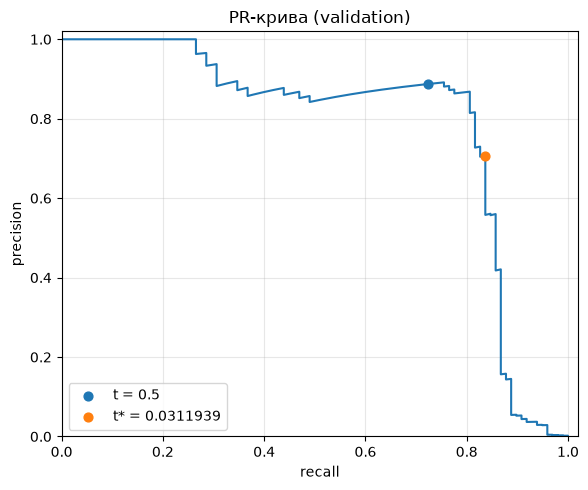

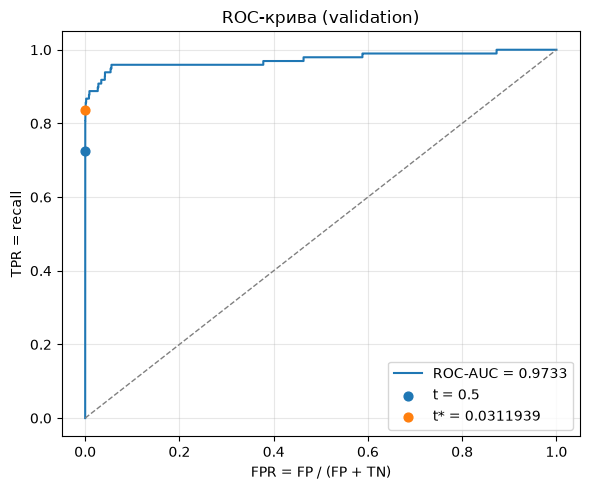

In [7]:
auc, fig_pr, fig_roc = plot_curves(validation["y"], validation["s"], curve_points(validation))
print(f"ROC-AUC = {auc:.6f}")

## 5. Перевірка пошуку порога на наборах A/B/C
Незалежний прямий перебір (`verification.py`, чистий Python, не імпортує `thresholds.py`) порівнюється з реалізацією через кумулятивні суми: усі лічильники, вартості й обраний поріг мають збігатися точно.

- **A** — рівні оцінки 0.7 з різними мітками: один кандидат, однаковий прогноз.
- **B** — немає позитивних міток: оптимум на граничному кандидаті $+\infty$.
- **C** — два кандидати з однаковою вартістю: обирається більший поріг.

In [8]:
checks, passed = run_verification()
for check in checks:
    s, y = verification.SETS[check["set"]]
    display(Markdown(
        f"**Набір {check['set']}**: `s = {s}`, `y = {y}`\n\n"
        + verification_table(check) + "\n\n" + verification_verdict(check)
    ))
print("Усі три перевірки пройдені:", passed)
assert passed, "Перевірка не пройдена: тестова оцінка не виконується"


**Набір A**: `s = [0.9, 0.7, 0.7, 0.4, 0.2, 0.1]`, `y = [0, 1, 0, 1, 0, 0]`

| Поріг | TP перебір | FP перебір | FN перебір | TN перебір | C перебір | TP кум. суми | FP кум. суми | FN кум. суми | TN кум. суми | C кум. суми | Збіг |
|---|---|---|---|---|---|---|---|---|---|---|---|
| +∞ | 0 | 0 | 2 | 4 | 20 | 0 | 0 | 2 | 4 | 20 | так |
| 0.9 | 0 | 1 | 2 | 3 | 21 | 0 | 1 | 2 | 3 | 21 | так |
| 0.7 | 1 | 2 | 1 | 2 | 12 | 1 | 2 | 1 | 2 | 12 | так |
| 0.4 | 2 | 2 | 0 | 2 | 2 | 2 | 2 | 0 | 2 | 2 | так |
| 0.2 | 2 | 3 | 0 | 1 | 3 | 2 | 3 | 0 | 1 | 3 | так |
| 0.1 | 2 | 4 | 0 | 0 | 4 | 2 | 4 | 0 | 0 | 4 | так |

t* (перебір) = 0.4; t* (кумулятивні суми) = 0.4; перевірка пройдена

**Набір B**: `s = [0.9, 0.6, 0.3]`, `y = [0, 0, 0]`

| Поріг | TP перебір | FP перебір | FN перебір | TN перебір | C перебір | TP кум. суми | FP кум. суми | FN кум. суми | TN кум. суми | C кум. суми | Збіг |
|---|---|---|---|---|---|---|---|---|---|---|---|
| +∞ | 0 | 0 | 0 | 3 | 0 | 0 | 0 | 0 | 3 | 0 | так |
| 0.9 | 0 | 1 | 0 | 2 | 1 | 0 | 1 | 0 | 2 | 1 | так |
| 0.6 | 0 | 2 | 0 | 1 | 2 | 0 | 2 | 0 | 1 | 2 | так |
| 0.3 | 0 | 3 | 0 | 0 | 3 | 0 | 3 | 0 | 0 | 3 | так |

t* (перебір) = +∞; t* (кумулятивні суми) = +∞; перевірка пройдена

**Набір C**: `s = [0.8, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.2]`, `y = [1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]`

| Поріг | TP перебір | FP перебір | FN перебір | TN перебір | C перебір | TP кум. суми | FP кум. суми | FN кум. суми | TN кум. суми | C кум. суми | Збіг |
|---|---|---|---|---|---|---|---|---|---|---|---|
| +∞ | 0 | 0 | 2 | 11 | 20 | 0 | 0 | 2 | 11 | 20 | так |
| 0.8 | 1 | 0 | 1 | 11 | 10 | 1 | 0 | 1 | 11 | 10 | так |
| 0.5 | 2 | 10 | 0 | 1 | 10 | 2 | 10 | 0 | 1 | 10 | так |
| 0.2 | 2 | 11 | 0 | 0 | 11 | 2 | 11 | 0 | 0 | 11 | так |

t* (перебір) = 0.8; t* (кумулятивні суми) = 0.8; перевірка пройдена

Усі три перевірки пройдені: True


## 6. Тестова оцінка
Поріг $t^*$ зафіксовано на validation; масиви test читаються вперше лише тут, після проходження перевірок.
$$\text{precision} = \frac{TP}{TP + FP}, \qquad \text{recall} = \frac{TP}{TP + FN}$$
Якщо знаменник нульовий, метрика не визначена.

In [9]:
test = evaluate_test(data, t_star)
display(Markdown(test_metrics_table(test)))
display(Markdown(test_confusion_table(test)))
print("precision =", fmt(test["precision"]), "  recall =", fmt(test["recall"]), "  C =", test["confusion"]["C"])

| Поріг | TP | FP | FN | TN | C | precision | recall |
|---|---|---|---|---|---|---|---|
| 0.0311939 | 80 | 43 | 19 | 56820 | 233 | 0.650407 | 0.808081 |

|  | Прогноз 1 | Прогноз 0 |
|---|---|---|
| Мітка 1 | TP = 80 | FN = 19 |
| Мітка 0 | FP = 43 | TN = 56820 |

precision = 0.650407   recall = 0.808081   C = 233


In [10]:
display(Markdown("Довідково, для висновків (не використовується для вибору порога):\n\n" + test_reference_table(test)))

Довідково, для висновків (не використовується для вибору порога):

| Поріг на test | TP | FP | FN | TN | C |
|---|---|---|---|---|---|
| 0.5 | 71 | 8 | 28 | 56855 | 288 |
| 0.0311939 | 80 | 43 | 19 | 56820 | 233 |
| +∞ | 0 | 0 | 99 | 56863 | 990 |

## 7. Приклади помилок на test
Перші п'ять FP і перші п'ять FN за номером рядка CSV, далі — зведення за всіма помилками.

In [11]:
display(Markdown(error_examples_table(test["examples"])))
display(Markdown(error_summary_table(test["errors"])))

| Рядок CSV (від 0, без заголовка) | Тип помилки | Мітка | Оцінка s | Amount | s − t* |
|---|---|---|---|---|---|
| 460 | FP | 0 | 0.196159 | 2.00 | +0.164965 |
| 2961 | FP | 0 | 0.0809608 | 2.49 | +0.0497669 |
| 10783 | FP | 0 | 0.966327 | 89.99 | +0.935133 |
| 13405 | FP | 0 | 0.932032 | 89.99 | +0.900838 |
| 13617 | FP | 0 | 0.922762 | 89.99 | +0.891568 |
| 10497 | FN | 1 | 0.0114643 | 3.79 | -0.0197296 |
| 52521 | FN | 1 | 0.00637309 | 105.99 | -0.0248208 |
| 55401 | FN | 1 | 0.00564157 | 1.00 | -0.0255524 |
| 91671 | FN | 1 | 0.000500423 | 290.18 | -0.0306935 |
| 93486 | FN | 1 | 0.0183515 | 0.00 | -0.0128424 |

| Тип | Кількість | Amount: медіана | Amount: середнє | Amount: min – max | abs(s − t*): медіана | abs(s − t*): min | abs(s − t*): max |
|---|---|---|---|---|---|---|---|
| FP | 43 | 2.49 | 110.98 | 0.00 – 1000.00 | 0.02499 | 0.000191819 | 0.935133 |
| FN | 19 | 33.76 | 161.99 | 0.00 – 829.41 | 0.0291183 | 0.00970319 | 0.0311448 |

**Підсумок:** числа вище отримано виконанням коду на `results/` і вони збігаються з таблицями в `README.md` та `analysis/report.md`; пояснення й висновки — у README.